# Tutorial: becas y apoyos educativos en Bogotá con web scraping

**Taller de Python · Facultad de Economía · Universidad de los Andes**

**Integrantes**

- Daniel Eduardo Ramírez Hoyos — 202626865
- Daniel Ricardo Valderrama Celis — 20213250

**Contenido:** 0. Introducción · 1. Paquetes y configuración · 2. Fuentes · 3. Extracción y caché · 4. Limpieza y validación · 5. Análisis · 6. App en Streamlit · 7. Limitaciones · 8. Uso de IA para ir más allá de la metodología · 9. Conclusiones

## 0. Introducción

Este tutorial muestra cómo reunir con web scraping la oferta de becas y apoyos educativos de tres entidades y compararla.
Primero planteamos el problema y la pregunta; cada sección siguiente construye una parte de la respuesta.

**Problema.** La información sobre becas y apoyos educativos para estudiar en Bogotá está repartida en portales distintos (fichas web, documentos PDF y plataformas con inicio de sesión), con formatos y fechas diferentes. Buscarla toma tiempo y hace fácil perder una convocatoria o postularse a una que ya venció.

**Pregunta.** ¿Cómo se comparan las becas y apoyos educativos publicados por la Universidad de los Andes, la Agencia Atenea y el SENA, a la fecha de extracción, en cobertura, requisitos y vigencia de sus convocatorias?

**Alcance.**

- *Término:* usamos "becas y apoyos educativos" para todo lo que se compara: becas, créditos, descuentos y la formación gratuita del SENA, que no es una beca.
- *Población:* oferta publicada para estudiar en Bogotá (en el SENA, programas con oferta en Bogotá).
- *Periodo:* una sola foto, tomada el 18 de noviembre de 2026 (fecha de extracción).
- *Variables:* cobertura (qué cubre), requisitos (qué se pide) y vigencia (fechas y estado de la convocatoria).

**Cómo atendemos las recomendaciones de la evaluación de la propuesta**

| Recomendación | Dónde se atiende |
|---|---|
| 1. Pregunta que permita responder algo concreto sobre las oportunidades educativas | Pregunta de esta sección; respuesta en las secciones 5 y 9 |
| 2. Extracción de los PDF de Atenea, verificación del acceso a SICORE y al contenido dinámico, enlaces de las secciones de convocatorias | Secciones 2 y 3 |
| 3. Justificar dónde se necesita Selenium y dónde bastan herramientas sencillas; organizar los datos con pandas | Sección 2 (y pandas en todo el tutorial) |
| 4. Identificar convocatorias vencidas y validar la vigencia de requisitos, fechas y enlaces | Sección 4 |
| 5. Unificar el término "becas y apoyos educativos" | Título, problema y pregunta |

## 1. Paquetes y configuración

Con la pregunta definida, cargamos en una sola celda los paquetes que usa el tutorial.
Las funciones largas de extracción y limpieza viven en `utils/scrapers.py`, para que el notebook se lea como un relato.

- `pandas`: organiza todos los datos en DataFrames (esquema común, limpieza y tablas de análisis).
- `matplotlib`: gráficos del análisis.
- `utils.scrapers`: funciones del proyecto. Por dentro usan `requests` (descargas), `BeautifulSoup` (lectura del HTML) y `pdfplumber` (lectura de los PDF de Atenea).
- `streamlit` no se importa aquí: lo usa la app (`app.py`), que se explica en la sección 6.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

from utils import scrapers

`ACTUALIZAR_DATOS` controla de dónde salen los datos:

- `False` (por defecto): todo se lee de las copias guardadas en `data/raw/` y `results/`. El tutorial corre sin internet y da siempre el mismo resultado.
- `True`: vuelve a raspar las tres fuentes (unos 25 minutos por las pausas entre solicitudes) y a validar los enlaces, y sobrescribe las copias.

El tutorial no tiene pasos aleatorios, así que no hace falta fijar una semilla.

In [2]:
ACTUALIZAR_DATOS = False
pd.set_option("display.max_colwidth", 90)

## 2. Fuentes: reconocimiento y elección de herramientas

Antes de raspar revisamos cada fuente: qué permite su `robots.txt`, si el contenido viene en el HTML o se arma con JavaScript, y si hay PDF o inicio de sesión.
Esa revisión decide qué herramienta usar en cada caso y qué queda fuera del alcance.

La revisión la hizo `scripts/01_reconocimiento_fuentes.py`, que consulta las páginas en línea, y guardó su resultado en `results/reconocimiento_fuentes.csv`. Aquí leemos esa tabla.

In [3]:
reconocimiento = pd.read_csv("results/reconocimiento_fuentes.csv")
reconocimiento[["fuente", "url_convocatorias", "contenido_en_html", "pdf", "requiere_login", "herramienta"]]

,fuente,url_convocatorias,contenido_en_html,pdf,requiere_login,herramienta
0,Universidad de los Andes (Apoyo Financiero),https://apoyofinanciero.uniandes.edu.co/explora-apoyos-financieros,Parcial. El buscador de 'Explora' es un iframe (https://apoyofinanciero.uniandes.edu.c...,"Sí, reglamentos en PDF; no hacen falta para el esquema (cobertura y fechas están en la...",No,requests + BeautifulSoup
1,Agencia Atenea (portal de convocatorias),https://www.agenciaatenea.gov.co/convocatorias,"Sí. 7 páginas (?page=0 a 6), 15 tarjetas en la primera, cada una con su estado. 15 de ...",Sí. 12 de 15 convocatorias enlazan PDF y 10 publican un 'lineamiento operativo' con lo...,No para consultar; la inscripción se hace en SICORE.,requests + BeautifulSoup; pdfplumber para los PDF
2,Agencia Atenea (SICORE),https://sicore.agenciaatenea.gov.co/,No. Sin JavaScript la página solo tiene 20 caracteres de texto (aplicación que se arma...,No,Sí. 2 convocatorias de Atenea indican ingresar con usuario y contraseña.,Fuera del alcance
3,SENA (Betowa),https://betowa.sena.edu.co/oferta,Sí. El servidor arma la página (Next.js): 490 programas en 49 páginas de 10 (?page=N)....,No,No para consultar; para inscribirse sí (inferido por los botones 'Ingresar' y 'Registr...,requests + BeautifulSoup


**Secciones de convocatorias de cada entidad**

| Entidad | Sección | Lo que se recorre |
|---|---|---|
| Universidad de los Andes | https://apoyofinanciero.uniandes.edu.co/explora-apoyos-financieros | Fichas listadas en https://apoyofinanciero.uniandes.edu.co/sitemap.xml |
| Agencia Atenea | https://www.agenciaatenea.gov.co/convocatorias | Listado (`?page=0` a `?page=6`), detalle de cada convocatoria y PDF de lineamiento |
| Agencia Atenea (SICORE) | https://sicore.agenciaatenea.gov.co/ | Nada: exige usuario y contraseña |
| SENA (Betowa) | https://betowa.sena.edu.co/oferta | Listado filtrado a Bogotá: `https://betowa.sena.edu.co/oferta?location=57011001&page_size=100&page=N` |

**¿Dónde hace falta Selenium y dónde bastan herramientas más sencillas?**

Selenium sirve cuando la información solo aparece después de que el navegador ejecuta JavaScript. Revisamos fuente por fuente:

- **Uniandes.** El buscador de "Explora" es un iframe que se arma con JavaScript, pero su `index.html` está bloqueado en `robots.txt`: usar Selenium ahí no estaría permitido. Tampoco hace falta, porque cada apoyo tiene una ficha estática listada en el `sitemap.xml`. Herramienta: `requests` + `BeautifulSoup`.
- **Atenea.** El listado y el detalle son HTML estático (Drupal), y las fechas vienen en etiquetas `<time datetime>`. Los requisitos suelen estar en un PDF de "lineamiento operativo". Herramientas: `requests` + `BeautifulSoup`, y `pdfplumber` para los PDF.
- **SENA Betowa.** Es un sitio hecho con JavaScript (Next.js), pero el servidor entrega los programas ya armados en el HTML, y la paginación y el filtro de ciudad van en la URL. Lo comprobamos comparando: la respuesta de `requests` trae los mismos 10 programas por página que muestra el navegador. Herramienta: `requests` + `BeautifulSoup`.
- **SICORE.** Es una aplicación de JavaScript con inicio de sesión. Selenium podría abrirla, pero los datos están detrás de una cuenta y no son públicos, así que queda fuera del alcance.

Conclusión: ninguna fuente pública necesita Selenium. Preferimos `requests`, que es más rápido, más fácil de reproducir y menos frágil ante cambios de diseño. Todos los datos se organizan con `pandas` en un esquema común.

**¿Cómo verificamos el acceso a SICORE y al contenido dinámico?**

- *SICORE:* sin ejecutar JavaScript, la página solo tiene 20 caracteres de texto. Además, las propias convocatorias de Atenea indican que hay que ingresar "con el usuario y contraseña creados en su inscripción".
- *Betowa:* contamos los programas en la respuesta de `requests` y los comparamos con el navegador. Usamos el navegador una sola vez para identificar los parámetros del filtro de Bogotá (`location=57011001`) y del tamaño de página (`page_size=100`).

**¿Cómo extraemos los PDF de Atenea?**

- Solo se descargan los PDF de "lineamiento operativo" de las convocatorias que no están finalizadas: a quien busca hoy no le sirven los requisitos de una convocatoria cerrada.
- `pdfplumber` extrae el texto y la función `scrapers.extraer_requisitos_pdf` busca el título "Requisitos … de participación". Descarta las líneas del índice y las definiciones del glosario, y corta la sección en el siguiente título numerado (máximo 3.000 caracteres).

## 3. Extracción y caché

Con la herramienta de cada fuente definida, extraemos los datos a un esquema común.
Guardamos copias crudas con su fecha, para que el tutorial corra sin internet y se pueda rastrear de dónde salió cada dato.

**Descarga (`scrapers.descargar_*`).** Para cada fuente:

- Lee el `robots.txt` y omite lo que no está permitido.
- Espera 2 segundos entre solicitudes.
- Guarda cada respuesta en `data/raw/<fuente>/`: el HTML comprimido (`.html.gz`) y los PDF tal cual.
- Escribe un `manifiesto.csv` con la URL, el archivo, el código HTTP y la fecha de extracción.

**Lectura (`scrapers.leer_*`).** Convierte los archivos crudos en un DataFrame con el esquema común: `nombre`, `entidad`, `tipo`, `cobertura`, `requisitos`, `fecha_apertura`, `fecha_cierre`, `enlace`, `fuente_url` y `fecha_extraccion`. Lo que una fuente no publica queda como `NaN`; nunca se rellena con datos inventados.

In [4]:
if ACTUALIZAR_DATOS:
    scrapers.descargar_uniandes()
    scrapers.descargar_atenea()
    scrapers.descargar_betowa()

# Resumen de lo que hay en la caché: fecha de extracción y archivos por tipo de página.
pd.DataFrame({fuente: scrapers.leer_manifiesto(fuente).groupby("tipo_pagina").size()
              for fuente in ["uniandes", "atenea", "betowa"]}).fillna(0).astype(int)

,uniandes,atenea,betowa
tipo_pagina,,,
detalle,0,68,231
ficha,30,0,0
lineamiento,0,4,0
listado,0,8,3
sitemap,1,0,0


Cómo se llena el esquema en cada fuente:

- **Uniandes:** una fila por ficha que publica una sección de cobertura ("Cobertura" o "Cubre"); las demás páginas del sitemap (menús, contacto, entidades financieras) se descartan.
  - `requisitos` sale de la sección de elegibilidad: "Programas a los que aplica" o "Dirigido a".
- **Atenea:** una fila por convocatoria.
  - `cobertura` es la descripción del beneficio.
  - `requisitos` sale del HTML cuando existe; si no, del PDF de lineamiento.
  - Además se guarda el estado que publica Atenea (`estado_publicado`), para validar después.
- **SENA:** una fila por programa con oferta en Bogotá. Betowa no publica fechas de inscripción: esas columnas quedan en `NaN`, y se guardan aparte los períodos académicos de los cursos (`periodos_cursos`).
- **`tipo`:** se asigna con una regla explícita (`scrapers.clasificar_tipo`). Es "formación gratuita" si el texto lo dice, "beca" si menciona beca, y en otro caso "apoyo financiero".

In [5]:
uniandes, paginas_descartadas = scrapers.leer_uniandes()
atenea = scrapers.leer_atenea()
betowa = scrapers.leer_betowa()
becas_apoyos = pd.concat([uniandes, atenea, betowa], ignore_index=True)
becas_apoyos.to_csv("results/extraccion_sin_limpiar.csv", index=False, encoding="utf-8-sig")
becas_apoyos.groupby(["entidad", "tipo"]).size().to_frame("registros")

Uniandes: 18 apoyos; 11 páginas sin sección de cobertura descartadas


Atenea: 68 convocatorias


Betowa: 231 programas en Bogotá


registros
entidad                  tipo                         
Agencia Atenea           apoyo financiero           40
                         beca                       24
                         formación gratuita          4
SENA                     formación gratuita        231
Universidad de los Andes apoyo financiero           11
                         beca                        7

Una muestra de dos registros por entidad, todavía sin limpiar (las fechas siguen en el formato en que se publican):

In [6]:
becas_apoyos.groupby("entidad").head(2)[["entidad", "nombre", "tipo", "cobertura", "requisitos",
                                         "fecha_apertura", "fecha_cierre"]]

,entidad,nombre,tipo,cobertura,requisitos,fecha_apertura,fecha_cierre
0,Universidad de los Andes,Apoyo Financiero Maestrias Virtuales (Alianza Coursera),apoyo financiero,"Cubre hasta el 15% del valor de la matrícula, según la necesidad económica del solicit...",Maestría en Inteligencia Analítica de Datos Maestría en Ingeniería de Software Maestrí...,15 de septiembre de 2026,6 de diciembre de 2026
1,Universidad de los Andes,APOYO IMPACTO PAÍS,apoyo financiero,"Cubre hasta el 90% del valor de la matrícula, según la necesidad económica del solicit...","Todos los programas Doctorales, excepto el doctorado en gestión de la innovación tecno...",NaN,NaN
18,Agencia Atenea,Convocatoria Jóvenes a la E: Formación para el Trabajo 5,apoyo financiero,"Está dirigida a jóvenes entre los 14 y 28 años, bachilleres egresados de colegios de B...",NaN,2026-12-02T08:00:00-05:00,2026-12-09T21:00:00-05:00
19,Agencia Atenea,Fondo Técnica y Tecnológica,apoyo financiero,Brinda subsidios para facilitar el acceso a la educación superior a egresados de coleg...,NaN,2026-12-14T08:00:00-05:00,2027-01-15T21:00:00-05:00
86,SENA,ACCIONES BASICAS PARA LA ATENCION DE UNA PERSONA CON AFECTACION DE LA SALUD,formación gratuita,"Formación gratuita del SENA. Complementaria , Complementaria virtual, 40 horas ",Edad mínima: 14 años.  Se requiere que el aprendiz ava (ambientes virtuales de aprend...,NaN,NaN
87,SENA,ACCIONES DE PREVENCION EN SALUD MENTAL,formación gratuita,"Formación gratuita del SENA. Complementaria , Complementaria virtual, 40 horas ",Edad mínima: 14 años.  Se requiere que el aprendiz ava (ambientes virtuales de aprend...,NaN,NaN


## 4. Limpieza y validación

La extracción deja texto crudo y fechas en formatos distintos según la fuente.
Aquí revisamos tipos, faltantes, duplicados y atípicos, y construimos las variables de vigencia (estado y enlace válido) que usa el análisis.

### 4.1 Tipos y faltantes

Todas las columnas llegan como texto, porque cada fuente publica las fechas en un formato distinto. Los faltantes **no se rellenan**: un `NaN` significa que la entidad no publica ese dato, y eso también es un resultado (ver la sección 5).

In [7]:
COLUMNAS_TEXTO = ["nombre", "cobertura", "requisitos"]
COLUMNAS_FECHA = ["fecha_apertura", "fecha_cierre", "fecha_extraccion"]

print(becas_apoyos.dtypes.value_counts().to_dict())
becas_apoyos[COLUMNAS_TEXTO + COLUMNAS_FECHA].isna().groupby(becas_apoyos["entidad"]).sum()

{<StringDtype(na_value=nan)>: 9, dtype('O'): 4}


,nombre,cobertura,requisitos,fecha_apertura,fecha_cierre,fecha_extraccion
entidad,,,,,,
Agencia Atenea,0,0,62,2,5,0
SENA,0,0,0,231,231,0
Universidad de los Andes,0,0,2,16,16,0


### 4.2 Duplicados

Un registro está duplicado si repite el enlace. Los nombres repetidos con enlaces distintos son aperturas distintas del mismo programa (por ejemplo, dos convocatorias del mismo fondo en fechas distintas) y se conservan.

In [8]:
print("Filas idénticas:", becas_apoyos.duplicated().sum(), "| enlaces repetidos:", becas_apoyos["enlace"].duplicated().sum())
becas_apoyos = becas_apoyos.drop_duplicates(subset="enlace")
becas_apoyos[becas_apoyos.duplicated(["entidad", "nombre"], keep=False)][["entidad", "nombre", "fecha_apertura", "enlace"]]

Filas idénticas: 0 | enlaces repetidos: 0


,entidad,nombre,fecha_apertura,enlace
43,Agencia Atenea,Fondo para Víctimas del Conflicto,2025-12-04,https://www.agenciaatenea.gov.co/convocatorias/fondo-para-victimas-del-conflicto-0
54,Agencia Atenea,Fondo para Víctimas del Conflicto,2025-06-05,https://www.agenciaatenea.gov.co/convocatorias/fondo-para-victimas-del-conflicto


### 4.3 Texto y fechas

- **Texto:** se quitan caracteres invisibles (algunas páginas de Atenea tienen espacios de ancho cero), espacios repetidos y espacios antes de las comas. No se cambia el contenido.
- **Fechas:** pasan a `datetime` en hora de Bogotá. Atenea publica en formato ISO con zona horaria (`2026-11-24T23:59:00-05:00`) o solo la fecha; Uniandes, como "26 de noviembre de 2026". La función `scrapers.texto_a_fecha` acepta los dos formatos y devuelve `NaT` si no reconoce uno, para no inventar fechas.
- **Comprobación:** contamos cuántas fechas publicadas no se pudieron convertir.

In [9]:
for columna in COLUMNAS_TEXTO:
    becas_apoyos[columna] = becas_apoyos[columna].map(scrapers.limpiar_cadena)

fechas_sin_convertir = {}
for columna in COLUMNAS_FECHA:
    convertidas = becas_apoyos[columna].map(scrapers.texto_a_fecha)
    fechas_sin_convertir[columna] = int((becas_apoyos[columna].notna() & convertidas.isna()).sum())
    becas_apoyos[columna] = pd.to_datetime(convertidas)
becas_apoyos["fin_periodo"] = pd.to_datetime(becas_apoyos["periodos_cursos"].map(scrapers.fin_ultimo_periodo))
print("Fechas publicadas que no se pudieron convertir:", fechas_sin_convertir)
becas_apoyos[COLUMNAS_FECHA].dtypes

Fechas publicadas que no se pudieron convertir: {'fecha_apertura': 0, 'fecha_cierre': 0, 'fecha_extraccion': 0}


fecha_apertura      datetime64[us]
fecha_cierre        datetime64[us]
fecha_extraccion    datetime64[us]
dtype: object

### 4.4 Valores atípicos en las fechas

Buscamos dos tipos de valores raros: cierres anteriores a la apertura (un error de publicación) y ventanas de inscripción muy largas. No se borran; si aparecen, se marcan como alerta en la sección 4.8.

In [10]:
becas_apoyos["dias_ventana"] = (becas_apoyos["fecha_cierre"] - becas_apoyos["fecha_apertura"]).dt.days
print("Cierres antes de la apertura:", int((becas_apoyos["dias_ventana"] < 0).sum()))
becas_apoyos.groupby("entidad")["dias_ventana"].describe().round(1)

Cierres antes de la apertura: 0


,count,mean,std,min,25%,50%,75%,max
entidad,,,,,,,,
Agencia Atenea,63.0,27.7,27.6,2.0,7.0,18.0,32.0,115.0
SENA,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Universidad de los Andes,2.0,67.0,21.2,52.0,59.5,67.0,74.5,82.0


No hay cierres anteriores a la apertura. Las ventanas más largas de Atenea (más de 90 días) corresponden a convocatorias para proyectos de investigación, que salen del alcance en el paso siguiente. Son plazos reales, no errores.

### 4.5 Alcance: becas y apoyos educativos para personas

La pregunta es sobre apoyos para estudiar. Algunas convocatorias de Atenea financian proyectos de investigación, empresas (Mipymes) o prácticas laborales: no son apoyos educativos para una persona y se excluyen.

La regla es explícita (`scrapers.PATRON_NO_ESTUDIANTES`). "Prácticas laborales" solo cuenta si aparece en el nombre, porque algunos programas de formación la mencionan como un beneficio más. La lista de excluidas se muestra para que se pueda verificar.

In [11]:
para_personas = [scrapers.dirigido_a_personas(n, c) for n, c in zip(becas_apoyos["nombre"], becas_apoyos["cobertura"])]
excluidas = becas_apoyos.loc[[not x for x in para_personas], ["entidad", "nombre"]]
becas_apoyos = becas_apoyos[para_personas].reset_index(drop=True)
print(f"Se excluyen {len(excluidas)} convocatorias; quedan {len(becas_apoyos)} registros.")
excluidas

Se excluyen 14 convocatorias; quedan 303 registros.


,entidad,nombre
24,Agencia Atenea,"Retos de Investigación en Salud, Vejez y Envejecimiento 2026"
37,Agencia Atenea,Programa Bogotá Científica Convocatoria Retos de Investigación en Salud - Sustancias P...
38,Agencia Atenea,LISTOS para '+MAS Bienestar' 2026
47,Agencia Atenea,Retos de innovación Academia Atenea
51,Agencia Atenea,LISTOS para 'MAS Bienestar'
62,Agencia Atenea,Prácticas laborales en la Agencia Atenea - Periodo 2025-I
63,Agencia Atenea,COOPERACIÓN PARA EL DISEÑO Y EJECUCIÓN DE PROYECTOS DE INVESTIGACIÓN ENFOCADOS EN LA S...
66,Agencia Atenea,Convocatoria Investigación para la toma de decisiones en salud mental en Bogotá
73,Agencia Atenea,"Convocatoria EcoCambio – Bogotá, ejemplo global de sostenibilidad"
76,Agencia Atenea,Convocatoria Cooperación para la gestión y ejecución de proyectos de investigación en ...


### 4.6 Vigencia: estado de cada convocatoria a la fecha de extracción

Así identificamos las convocatorias vencidas y validamos la vigencia de las fechas (`scrapers.calcular_estado`):

1. **Con fecha de cierre publicada:**
   - "próxima" si todavía no abre;
   - "abierta" si cierra el día de la extracción o después;
   - "cerrada" (vencida) si ya cerró.
2. **Sin fecha de cierre, pero con un estado publicado por la entidad (Atenea):** se usa ese estado.
3. **SENA:** si el período académico de todos sus cursos ya terminó, el programa queda como "cerrada" (inferido). Es oferta vencida que sigue publicada.
4. **En otro caso:** "sin fecha".

Agregamos "próxima" a abierta, cerrada y sin fecha, porque Atenea publica convocatorias que todavía no abren: con solo la fecha de cierre parecerían abiertas. La columna `criterio_estado` dice qué regla se aplicó a cada registro.

In [12]:
becas_apoyos[["estado", "criterio_estado"]] = becas_apoyos.apply(scrapers.calcular_estado, axis=1, result_type="expand")
pd.crosstab(becas_apoyos["entidad"], becas_apoyos["estado"])

estado,abierta,cerrada,próxima,sin fecha
entidad,,,,
Agencia Atenea,3,47,3,1
SENA,0,2,0,229
Universidad de los Andes,2,0,0,16


**Validación de las fechas.** Atenea publica su propio estado en el listado. Si nuestras fechas son correctas, el estado calculado debe coincidir con el publicado:

In [13]:
atenea_limpia = becas_apoyos[becas_apoyos["entidad"] == "Agencia Atenea"]
pd.crosstab(atenea_limpia["estado"], atenea_limpia["estado_publicado"])

estado_publicado,Apertura: Diciembre de 2026,En curso,Finalizada,Inscripciones abiertas
estado,,,,
abierta,0,0,0,3
cerrada,0,0,47,0
próxima,3,0,0,0
sin fecha,0,1,0,0


Coinciden en todos los casos comparables: lo que calculamos como "abierta", "cerrada" o "próxima" es lo que Atenea publica como "Inscripciones abiertas", "Finalizada" o "Apertura: …". La única convocatoria "En curso" no tiene fechas publicadas y queda "sin fecha".

**Vigencia de los requisitos.** Los requisitos se toman solo de la página de la propia convocatoria o del PDF de lineamiento enlazado desde ella, nunca de manuales de convocatorias anteriores. Cuando no hay requisitos, el registro queda marcado (sección 4.8) en lugar de completarse con otra fuente.

### 4.7 Validación de enlaces

Un enlace es válido si respondió con código HTTP 200. Con `ACTUALIZAR_DATOS = True`, `scrapers.validar_enlaces` visita cada enlace (respetando `robots.txt` y con pausas) y guarda el resultado en `results/validacion_enlaces.csv`. Con `False` se usa ese resultado guardado.

In [14]:
validacion = scrapers.validar_enlaces(becas_apoyos["enlace"], ACTUALIZAR_DATOS)
becas_apoyos = becas_apoyos.merge(validacion[["enlace", "codigo_http", "fecha_validacion"]], on="enlace", how="left")
becas_apoyos["enlace_valido"] = becas_apoyos["codigo_http"] == 200
becas_apoyos.groupby("entidad")["enlace_valido"].agg(validos="sum", total="count")

,validos,total
entidad,,
Agencia Atenea,54,54
SENA,231,231
Universidad de los Andes,18,18


### 4.8 Alertas de calidad y tabla final

Cada registro lleva una lista de lo que un aspirante debería verificar antes de confiar en él: falta de requisitos, falta de fecha de cierre, enlace no válido, cierre antes de la apertura o período vencido que sigue publicado.

En las convocatorias cerradas de Atenea, "sin requisitos" es esperado, porque sus PDF no se descargan. La tabla final queda en `results/becas_apoyos.csv` y es la que leen el análisis y la app.

In [15]:
def alertas_de(fila):
    """Lista de problemas de calidad de un registro (NaN si no tiene ninguno)."""
    alertas = []
    if pd.isna(fila["requisitos"]):
        alertas.append("sin requisitos")
    if pd.isna(fila["fecha_cierre"]):
        alertas.append("sin fecha de cierre")
    if not fila["enlace_valido"]:
        alertas.append("enlace no válido")
    if fila["dias_ventana"] < 0:
        alertas.append("cierre antes de apertura")
    if fila["criterio_estado"] == "período académico terminado (inferido)":
        alertas.append("período vencido aún publicado")
    return "; ".join(alertas) or float("nan")


becas_apoyos["alertas"] = becas_apoyos.apply(alertas_de, axis=1)
COLUMNAS_FINALES = scrapers.ESQUEMA + ["estado", "criterio_estado", "enlace_valido", "codigo_http",
                                       "fecha_validacion", "alertas", "dias_ventana", "estado_publicado",
                                       "requisitos_origen", "periodos_cursos", "fin_periodo"]
becas_apoyos = becas_apoyos[COLUMNAS_FINALES]
becas_apoyos.to_csv("results/becas_apoyos.csv", index=False, encoding="utf-8-sig")
becas_apoyos.groupby("entidad")["alertas"].value_counts(dropna=False).to_frame("registros")

registros
entidad                  alertas                                                      
Agencia Atenea           sin requisitos                                             45
                         NaN                                                         4
                         sin requisitos; sin fecha de cierre                         4
                         sin fecha de cierre                                         1
SENA                     sin fecha de cierre                                       229
                         sin fecha de cierre; período vencido aún publicado          2
Universidad de los Andes sin fecha de cierre                                        14
                         NaN                                                         2
                         sin requisitos; sin fecha de cierre                         2

## 5. Análisis: cobertura, requisitos y vigencia

Con la tabla limpia comparamos las tres entidades en las tres dimensiones de la pregunta: vigencia, cobertura y requisitos.
Cada resultado se interpreta en función de la pregunta. Las cifras corresponden a la extracción del 18 de noviembre de 2026.

Antes, definimos el estilo común de los gráficos: un color fijo por entidad (paleta Okabe-Ito, apta para daltonismo) y un pie que indica la fuente.

In [16]:
FECHA = becas_apoyos["fecha_extraccion"].max().strftime("%Y-%m-%d")
ENTIDADES = ["Universidad de los Andes", "Agencia Atenea", "SENA"]
COLOR_ENTIDAD = {"Universidad de los Andes": "#0072B2", "Agencia Atenea": "#E69F00", "SENA": "#009E73"}
PIE_FIGURA = f"Fuente: páginas de Uniandes, Atenea y SENA Betowa, extraídas el {FECHA}. Elaboración: tutorial.ipynb"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#888888", "axes.grid": True, "grid.color": "#E5E5E5",
                     "axes.axisbelow": True})


def guardar_figura(figura, nombre):
    """Agrega el pie de fuente, guarda la figura en figures/ y la muestra."""
    figura.tight_layout()
    figura.text(0.01, 0.0, PIE_FIGURA, fontsize=7, color="#666666", va="top")
    figura.savefig(f"figures/{nombre}", dpi=150, bbox_inches="tight")
    plt.show()


def porcentaje_por_entidad(indicadores, base):
    """% de registros de cada entidad cuyo texto cumple cada indicador (regla de palabras clave)."""
    tabla = pd.DataFrame({nombre: base.groupby("entidad")[columna].apply(
        lambda textos, patron=patron: textos.str.contains(patron, case=False, regex=True).mean() * 100)
        for nombre, (columna, patron) in indicadores.items()}).T
    return tabla[ENTIDADES].round(1)


def grafico_indicadores(tabla, titulo, eje_x, nombre):
    """Barras horizontales agrupadas: % por entidad para cada indicador."""
    tabla = tabla.drop(index=[i for i in tabla.index if i.endswith("(n)")])
    figura, eje = plt.subplots(figsize=(8, 0.75 * len(tabla) + 1.2))
    alto = 0.25
    for k, entidad in enumerate(ENTIDADES):
        posiciones = [i + (k - 1) * alto for i in range(len(tabla))]
        eje.barh(posiciones, tabla[entidad], height=alto, color=COLOR_ENTIDAD[entidad],
                 edgecolor="white", linewidth=1, label=entidad)
        for y, valor in zip(posiciones, tabla[entidad]):
            if valor > 0:
                etiqueta = "<1 %" if valor < 0.5 else f"{valor:.0f} %"
                eje.text(valor + 1, y, etiqueta, va="center", fontsize=7, color="#333333")
    eje.set_yticks(range(len(tabla)), tabla.index)
    eje.invert_yaxis()
    eje.set_xlim(0, 110)
    eje.set_xlabel(eje_x)
    eje.set_title(titulo, loc="left", pad=28)
    eje.grid(axis="y", visible=False)
    eje.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
    guardar_figura(figura, nombre)

### 5.1 Vigencia

Primero, cuántos registros de cada entidad están abiertos, próximos, cerrados o sin fecha, qué porcentaje publica fecha de cierre y cuánto dura la ventana de inscripción.

In [17]:
ESTADOS = ["abierta", "próxima", "cerrada", "sin fecha"]
vigencia = pd.crosstab(becas_apoyos["entidad"], becas_apoyos["estado"]).reindex(index=ENTIDADES, columns=ESTADOS, fill_value=0)
vigencia["total"] = vigencia.sum(axis=1)
vigencia["% con fecha de cierre publicada"] = (
    becas_apoyos.groupby("entidad")["fecha_cierre"].apply(lambda f: f.notna().mean() * 100).round(1))
vigencia["mediana de días de inscripción"] = becas_apoyos.groupby("entidad")["dias_ventana"].median()
vigencia.to_csv("results/tabla_vigencia.csv", encoding="utf-8-sig")
vigencia

estado,abierta,próxima,cerrada,sin fecha,total,% con fecha de cierre publicada,mediana de días de inscripción
entidad,,,,,,,
Universidad de los Andes,2,0,0,16,18,11.1,67.0
Agencia Atenea,3,3,47,1,54,90.7,14.0
SENA,0,0,2,229,231,0.0,NaN


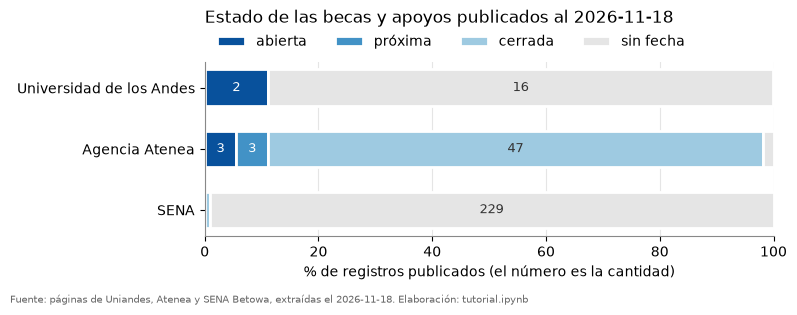

In [18]:
# Barras 100 % apiladas: una sola tonalidad, más oscuro = más vigente.
COLOR_ESTADO = {"abierta": "#08519C", "próxima": "#4292C6", "cerrada": "#9ECAE1", "sin fecha": "#E5E5E5"}
proporcion = vigencia[ESTADOS].div(vigencia["total"], axis=0) * 100
figura, eje = plt.subplots(figsize=(8, 3))
izquierda = pd.Series(0.0, index=ENTIDADES)
for estado in ESTADOS:
    eje.barh(ENTIDADES, proporcion[estado], left=izquierda, color=COLOR_ESTADO[estado],
             edgecolor="white", linewidth=2, label=estado, height=0.6)
    for entidad in ENTIDADES:
        if proporcion.loc[entidad, estado] >= 4:  # etiqueta solo en segmentos con espacio para el número
            eje.text(izquierda[entidad] + proporcion.loc[entidad, estado] / 2, entidad,
                     str(vigencia.loc[entidad, estado]), ha="center", va="center",
                     color="white" if estado in ("abierta", "próxima") else "#333333", fontsize=9)
    izquierda += proporcion[estado]
eje.invert_yaxis()
eje.set_xlim(0, 100)
eje.set_xlabel("% de registros publicados (el número es la cantidad)")
eje.set_title(f"Estado de las becas y apoyos publicados al {FECHA}", loc="left", pad=28)
eje.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
eje.grid(axis="y", visible=False)
guardar_figura(figura, "estado_por_entidad.png")

**Interpretación.** Las tres entidades informan la vigencia de forma muy distinta:

- **Atenea** trabaja por convocatorias cortas. Publica fecha de cierre en el 90,7 % de sus registros y la mediana de la ventana de inscripción es de 14 días. A la fecha hay 3 convocatorias abiertas y 3 próximas.
- **Uniandes** publica fechas solo en 2 de sus 18 apoyos (11,1 %), que son los 2 abiertos. Los otros 16 son líneas permanentes sin ventana publicada en la ficha: desde la página no se puede saber si hoy reciben solicitudes.
- **El SENA** no publica fechas de inscripción en Betowa (0 %). Además, 2 programas siguen publicados con períodos académicos que terminaron en 2015 y 2019: es oferta vencida que la página no distingue.

Ahora, para quien quiere postularse ya: ¿cuántos días quedan para cerrar las convocatorias abiertas y próximas?

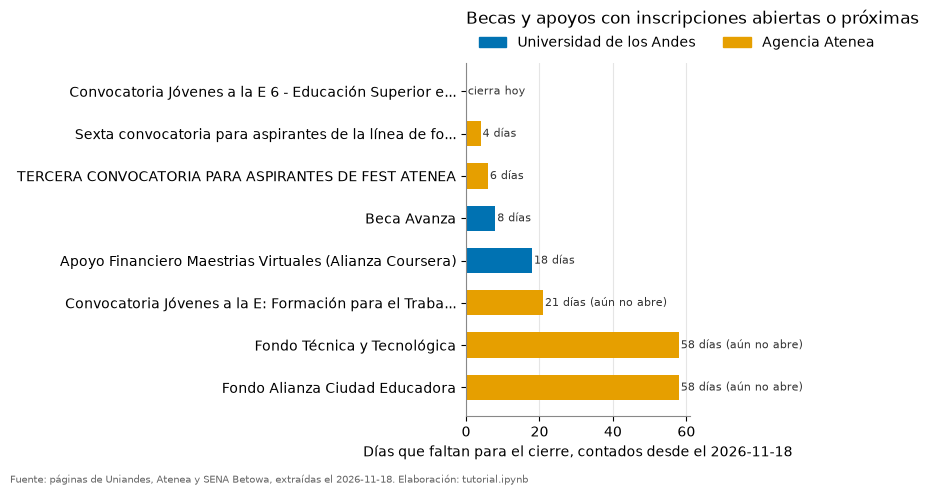

In [19]:
vigentes = becas_apoyos[becas_apoyos["estado"].isin(["abierta", "próxima"])].copy()
vigentes["dias_para_cierre"] = (vigentes["fecha_cierre"].dt.normalize() - vigentes["fecha_extraccion"]).dt.days
vigentes = vigentes.sort_values("dias_para_cierre")
vigentes[["entidad", "nombre", "tipo", "estado", "fecha_apertura", "fecha_cierre", "dias_para_cierre",
          "requisitos_origen", "enlace"]].to_csv("results/tabla_convocatorias_vigentes.csv", index=False, encoding="utf-8-sig")

figura, eje = plt.subplots(figsize=(8, 0.45 * len(vigentes) + 1.2))
etiquetas = [n if len(n) <= 55 else n[:52] + "..." for n in vigentes["nombre"]]
eje.barh(etiquetas, vigentes["dias_para_cierre"], color=vigentes["entidad"].map(COLOR_ENTIDAD), height=0.6)
for posicion, (dias, estado) in enumerate(zip(vigentes["dias_para_cierre"], vigentes["estado"])):
    texto = "cierra hoy" if dias == 0 else f"{dias} días"
    eje.text(dias + 0.5, posicion, texto + (" (aún no abre)" if estado == "próxima" else ""),
             va="center", fontsize=8, color="#333333")
eje.invert_yaxis()
eje.set_xlabel(f"Días que faltan para el cierre, contados desde el {FECHA}")
eje.set_title("Becas y apoyos con inscripciones abiertas o próximas", loc="left", pad=28)
eje.grid(axis="y", visible=False)
eje.legend(handles=[Patch(color=COLOR_ENTIDAD[e], label=e) for e in ENTIDADES if e in set(vigentes["entidad"])],
           frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
guardar_figura(figura, "dias_para_cierre.png")

**Interpretación.** Quien busque hoy tiene poco margen:

- De las 5 convocatorias abiertas, 3 cierran en 6 días o menos. Todas son de Atenea, y una cierra el mismo día de la extracción.
- Las de Uniandes tienen más plazo (8 y 18 días), pero son para posgrado.
- Las 3 próximas de Atenea abren en diciembre de 2026.

### 5.2 Cobertura

¿Qué cubre cada apoyo? Medimos si el texto de cobertura menciona cada componente, con reglas de palabras clave explícitas. Cuentan menciones; no miden montos ni cupos.

In [20]:
INDICADORES_COBERTURA = {
    "Matrícula": ("cobertura", r"matr[ií]cula"),
    "Hasta el 100 %": ("cobertura", r"100\s?%"),
    "Apoyo de sostenimiento": ("cobertura", r"sostenimiento|apoyo económico|manutenci|transporte"),
    "Crédito (condonable o no)": ("cobertura", r"cr[eé]dito|condonable|pr[eé]stamo"),
    "Descuento": ("cobertura", r"descuento"),
    "Formación sin costo": ("cobertura", r"gratuit"),
}
cobertura = porcentaje_por_entidad(INDICADORES_COBERTURA, becas_apoyos)
cobertura.loc["Registros (n)"] = becas_apoyos["entidad"].value_counts()[ENTIDADES]
cobertura.to_csv("results/tabla_cobertura.csv", encoding="utf-8-sig")
cobertura

entidad,Universidad de los Andes,Agencia Atenea,SENA
Matrícula,94.4,57.4,0.0
Hasta el 100 %,22.2,35.2,0.0
Apoyo de sostenimiento,0.0,53.7,0.0
Crédito (condonable o no),11.1,22.2,0.0
Descuento,5.6,0.0,0.0
Formación sin costo,0.0,25.9,100.0
Registros (n),18.0,54.0,231.0


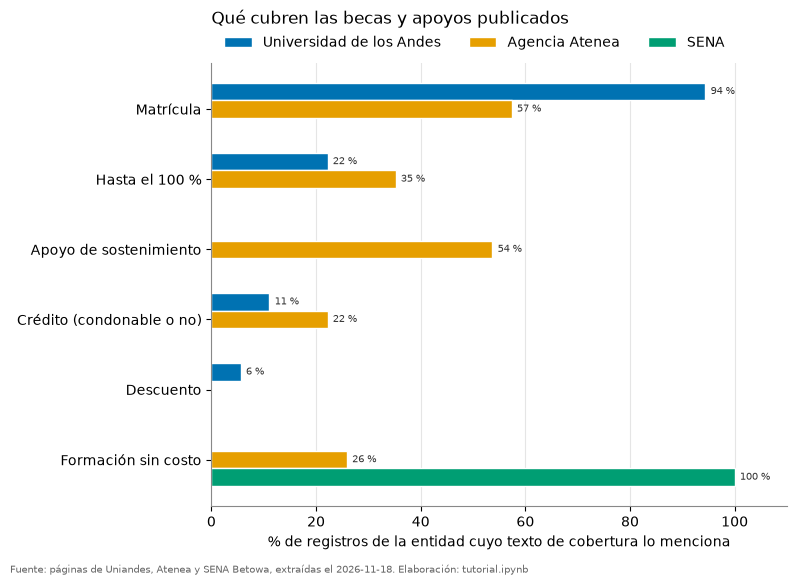

In [21]:
grafico_indicadores(cobertura, "Qué cubren las becas y apoyos publicados",
                    "% de registros de la entidad cuyo texto de cobertura lo menciona", "cobertura_por_entidad.png")

**Interpretación.** La cobertura distingue con claridad a las tres entidades:

- **Uniandes** concentra sus apoyos en la matrícula (94,4 %), a veces hasta el 100 %, con descuentos y créditos. Ninguno menciona apoyo de sostenimiento.
- **Atenea** combina matrícula (57,4 %) con apoyo de sostenimiento (53,7 %), y además ofrece créditos condonables (22,2 %) y formación gratuita (25,9 %). Es la oferta más variada en tipos de apoyo.
- **El SENA** ofrece formación gratuita (100 %), no becas. En Bogotá son cursos complementarios cortos: 227 de 231 duran 40 horas.

### 5.3 Requisitos

¿Qué piden para acceder? Usamos el mismo método, ahora sobre el texto de requisitos y solo entre los registros que publican requisitos. El denominador (n) de cada entidad aparece en la tabla y en el gráfico.

In [22]:
INDICADORES_REQUISITOS = {
    "Vivir o haber estudiado en Bogotá": ("requisitos", r"bogot[aá]"),
    "Edad mínima o máxima": ("requisitos", r"edad|\d+\)?\s+años"),
    "Ser bachiller o cursar grado 11": ("requisitos", r"bachiller|grado (?:once|11)"),
    "Prueba Saber 11 o ICFES": ("requisitos", r"saber 11|icfes"),
    "Estrato o Sisbén": ("requisitos", r"estrato|sisb[eé]n"),
    # "estudiantes" suelto no cuenta: el SENA lo usa para describir el público ("estudiantes, empresarios...").
    "Estar admitido o ser estudiante": ("requisitos", r"admitid|matriculad|ser estudiante|estudiantes? (?:de|que|nuevos|antiguos)"),
    "Manejo de herramientas digitales": ("requisitos", r"herramientas inform|ambientes virtuales"),
}
con_requisitos = becas_apoyos[becas_apoyos["requisitos"].notna()]
requisitos = porcentaje_por_entidad(INDICADORES_REQUISITOS, con_requisitos)
requisitos.loc["Registros con requisitos publicados (n)"] = con_requisitos["entidad"].value_counts()[ENTIDADES]
requisitos.loc["Registros totales (n)"] = becas_apoyos["entidad"].value_counts()[ENTIDADES]
requisitos.to_csv("results/tabla_requisitos.csv", encoding="utf-8-sig")
requisitos

entidad,Universidad de los Andes,Agencia Atenea,SENA
Vivir o haber estudiado en Bogotá,0.0,100.0,0.0
Edad mínima o máxima,6.2,80.0,100.0
Ser bachiller o cursar grado 11,6.2,80.0,0.4
Prueba Saber 11 o ICFES,0.0,80.0,0.0
Estrato o Sisbén,0.0,20.0,0.0
Estar admitido o ser estudiante,37.5,100.0,1.3
Manejo de herramientas digitales,0.0,0.0,85.3
Registros con requisitos publicados (n),16.0,5.0,231.0
Registros totales (n),18.0,54.0,231.0


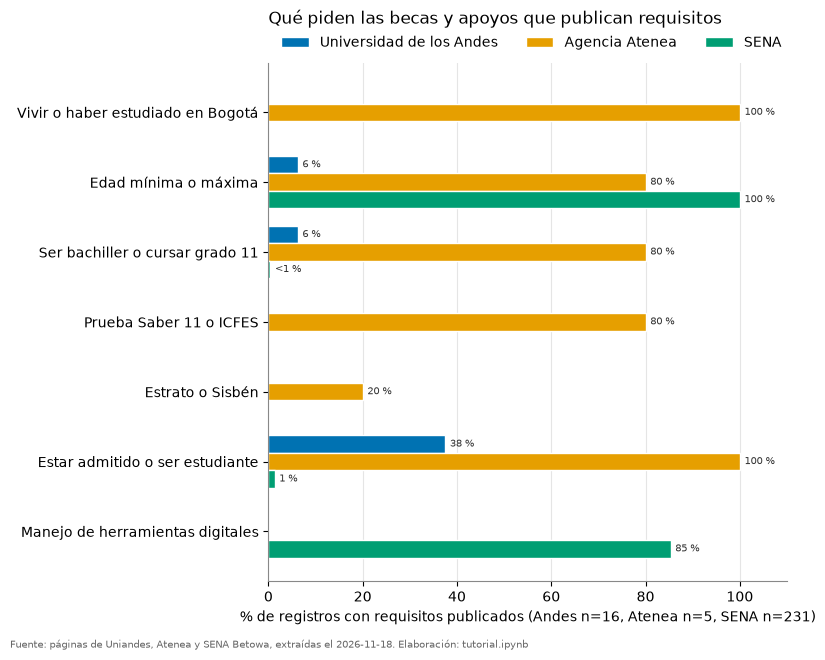

In [23]:
n_texto = ", ".join(f"{e.split()[-1]} n={int(requisitos.loc['Registros con requisitos publicados (n)', e])}"
                    for e in ENTIDADES)
grafico_indicadores(requisitos, "Qué piden las becas y apoyos que publican requisitos",
                    f"% de registros con requisitos publicados ({n_texto})", "requisitos_por_entidad.png")

**Interpretación.** Los requisitos marcan quién puede acceder:

- **Atenea** es la más exigente y la más focalizada. En sus 5 registros con requisitos publicados, todos mencionan Bogotá, y 4 de 5 piden ser bachiller o estar en grado 11, haber presentado Saber 11 y cumplir un límite de edad. Ojo: n = 5 (4 convocatorias vigentes y 1 finalizada que comparte el PDF), porque solo se descargaron los requisitos de la oferta actual. No describe el histórico.
- **Uniandes** pide sobre todo ser estudiante o estar admitido en un programa (37,5 %). En la ficha publica a qué programas aplica, no los criterios socioeconómicos, que están en el reglamento en PDF.
- **El SENA** casi no pone barreras: edad mínima de 14 años en los 231 programas y, en el 85,3 %, manejo básico de herramientas digitales (son cursos virtuales).

## 6. App en Streamlit

El análisis compara las entidades, pero un aspirante necesita encontrar rápido lo que le sirve.
Por eso la tabla limpia de la sección 4 alimenta una app de búsqueda, que no raspa nada y funciona sin internet.

**Qué hace `app.py`**

- Lee `results/becas_apoyos.csv`.
- Muestra una tabla con nombre, entidad, tipo, estado, fechas, cobertura, requisitos, alertas ("Verificar") y el enlace oficial.
- Tiene un buscador por texto en nombre, cobertura y requisitos, que no distingue tildes ni mayúsculas.
- Tiene filtros por entidad, tipo y estado. "Solo abiertas" viene activado por defecto.
- Recuerda la fecha de extracción y pide confirmar en el enlace oficial antes de postularse.

**Cómo correrla.** Desde una terminal ubicada en la carpeta del proyecto, con el entorno virtual activado:

```
streamlit run app.py
```

En Windows, sin activar el entorno: `.venv\Scripts\streamlit.exe run app.py`. La app se abre en http://localhost:8501 y se cierra con Ctrl+C en la terminal. Esta sección no ejecuta la app, porque Streamlit es un servidor web y bloquearía el notebook.

## 7. Limitaciones

Los resultados anteriores responden la pregunta para una fecha y unas fuentes concretas.
Estas son las limitaciones que hay que tener en cuenta al leerlos.

- **Una sola fecha.** Es una foto del 18 de noviembre de 2026. El estado de las convocatorias cambia cada día; con `ACTUALIZAR_DATOS = True` se obtiene una nueva foto, pero las conclusiones no se pueden extender a otras fechas sin repetir la extracción.
- **Fuentes que quedaron fuera.** SICORE (Atenea) exige usuario y contraseña, así que no se incluyen sus datos (por ejemplo, cupos o resultados). El buscador de Uniandes está bloqueado por `robots.txt`; usamos el sitemap, que podría no listar todos los apoyos.
- **Lo que las fuentes no publican.**
  - El SENA no publica fechas de inscripción: casi toda su oferta queda "sin fecha", y su vigencia no se puede comparar con la de las otras entidades.
  - Uniandes publica fechas en solo 2 de 18 fichas.
  - Ninguna fuente publica cupos de forma estructurada.
- **Requisitos incompletos.** En Atenea solo se leyeron los PDF de la oferta vigente (n = 5 con requisitos). De cada lineamiento se toma la primera sección de requisitos, recortada a 3.000 caracteres. En Uniandes se usa la sección de elegibilidad de la ficha, no el reglamento en PDF.
- **Indicadores por palabras clave.** Cobertura, requisitos y `tipo` se miden con reglas sobre el texto publicado. Cuentan menciones, no montos ni condiciones exactas, y pueden fallar con redacciones inesperadas. Por ejemplo, convocatorias de la misma familia (Jóvenes a la E) quedan unas como "beca" y otras como "apoyo financiero".
- **Alcance.** Son tres entidades, no toda la oferta de Bogotá (faltan otras universidades, ICETEX directo, fundaciones). En el SENA solo se incluye la oferta con filtro de Bogotá, que hoy es formación complementaria.
- **Cambios en las páginas.** Los extractores dependen de la estructura del HTML, los PDF y las URL de cada sitio. Si una entidad cambia su diseño, hay que ajustar las funciones de `utils/scrapers.py`.
- **Sin causalidad.** El análisis es descriptivo: compara lo que se publica y no dice nada sobre el efecto de los apoyos ni sobre quién los recibe.

## 8. Uso de IA para ir más allá de la metodología

### Prompt

### Respuesta de la IA

### Qué va más allá de lo recomendado

### Implementación y efecto

### Qué descartamos y por qué

## 9. Conclusiones

Con la vigencia, la cobertura y los requisitos ya medidos, respondemos la pregunta.
Al 18 de noviembre de 2026, las tres entidades ofrecen cosas distintas a públicos distintos, y publican su información con niveles de detalle muy diferentes.

- **Vigencia.**
  - Atenea es la única con convocatorias claramente fechadas (90,7 % con fecha de cierre), pero sus ventanas son cortas (mediana de 14 días). De sus 3 abiertas, todas cierran en 6 días o menos, y otras 3 abren en diciembre.
  - Uniandes tiene 2 apoyos abiertos con fecha (para posgrado) y 16 líneas permanentes sin ventana publicada.
  - El SENA no publica fechas de inscripción, y mantiene publicada oferta vencida.
- **Cobertura.**
  - Uniandes cubre sobre todo matrícula (94,4 %).
  - Atenea combina matrícula con apoyo de sostenimiento y créditos condonables: es la oferta más completa para quien no puede pagar sus gastos de estudio.
  - El SENA ofrece formación gratuita, en Bogotá hoy limitada a cursos complementarios cortos.
- **Requisitos.**
  - Atenea es la más focalizada: sus requisitos mencionan Bogotá y piden ser bachiller o estar en grado 11, Saber 11 y un límite de edad.
  - Uniandes pide ser o estar admitido como estudiante de programas específicos.
  - El SENA es la más abierta (14 años y manejo digital básico).

En síntesis: para un bachiller de Bogotá que necesita financiar la educación superior, Atenea ofrece la cobertura más amplia, pero exige estar atento a ventanas muy cortas. Uniandes ofrece apoyos sobre la matrícula para quienes ya están vinculados a la universidad. El SENA es la puerta de entrada con menos barreras, pero hoy, en Bogotá, solo con cursos cortos. La diferencia en cómo cada entidad publica fechas y requisitos es, en sí misma, una barrera de información: es justo lo que una herramienta unificada como la app de la sección 6 ayuda a reducir.